# 02. Training ResNet50 dan EfficientNet-B0

Kedua model memakai pipeline yang sama. Perbedaannya hanya backbone dan normalisasi input (lihat `src/models.py`).

| Komponen | Pengaturan |
|---|---|
| Input | 224 x 224 x 3, satu citra per sampel |
| Backbone | ImageNet, awalnya dibekukan |
| Head | GlobalAveragePooling, Dropout 0,4, Dense(1, sigmoid, L2 1e-4) |
| Loss | Binary crossentropy |
| Balancing | Oversampling katarak 3 kali lipat (hanya train) dan flip acak pada kelas katarak |
| Fase 1 | Backbone beku, LR 1e-4, maksimal 15 epoch |
| Fase 2 | 30 layer terakhir backbone dilatih, LR 1e-5, maksimal 25 epoch |
| Callback | Early stopping dan checkpoint memantau `val_auc`, patience 12 |

Semua nilai ada di `src/config.py`.

**Waktu.** Pada run di repositori ini (CPU, tanpa GPU), fase 1 memakan sekitar 73 detik per epoch untuk ResNet50 dan 34 detik untuk EfficientNet-B0.

**Prasyarat:** notebook 01 sudah dijalankan.

**Keluaran**
- `models/<Model>_best.keras`: bobot terbaik (tidak masuk Git).
- `results/history_<Model>.csv`: riwayat training kedua fase.
- `images/<Model>_training_history.png`.

In [1]:
import sys
from pathlib import Path

# Notebook dijalankan dari folder notebooks/. Akar repositori ada satu tingkat di atasnya.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings

import pandas as pd
import tensorflow as tf

from src import config, preprocessing, training, visualization

warnings.filterwarnings("ignore")

print("TensorFlow  :", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices("GPU"))

TensorFlow  : 2.21.0
GPU tersedia: []


## 1. Muat data latih dan validasi

Cache berisi citra CLAHE `uint8`. Normalisasi per backbone dilakukan di dalam `training.run_training`.

In [2]:
X_train, y_train = preprocessing.load_cache("train")
X_val, y_val = preprocessing.load_cache("val")

pd.DataFrame([
    {"split": "train", "shape": str(X_train.shape), "katarak": int((y_train == 1).sum()), "normal": int((y_train == 0).sum())},
    {"split": "val",   "shape": str(X_val.shape),   "katarak": int((y_val == 1).sum()),   "normal": int((y_val == 0).sum())},
])

,split,shape,katarak,normal
0,train,"(2153, 224, 224, 3)",221,1932
1,val,"(466, 224, 224, 3)",47,419


## 2. Balancing data latih

Rasio awal Normal : Katarak pada train sekitar 1 : 8,7. Dua langkah dipakai:
1. **Oversampling.** Indeks citra katarak diulang 3 kali, sehingga jumlahnya menjadi 4 kali lipat. Rasio menjadi sekitar 1 : 2,9.
2. **Augmentasi.** Flip horizontal dan vertikal acak, hanya untuk citra berlabel katarak. Duplikat tidak identik di tiap epoch.

Val dan test tidak disentuh. Fungsi `training.run_training` menjalankan kedua langkah ini. Sel berikut hanya menunjukkan hasil oversampling.

In [3]:
_, y_bal = training.oversample_minority(X_train, y_train)
nc, nn = int((y_bal == 1).sum()), int((y_bal == 0).sum())
print(f"Train setelah oversampling: {len(y_bal)} citra | katarak {nc} | normal {nn} | rasio 1:{nn / nc:.2f}")
del _, y_bal

Train setelah oversampling: 2595 citra | katarak 663 | normal 1932 | rasio 1:2.91


## 3. ResNet50

In [4]:
model, hist_resnet = training.run_training("ResNet50", X_train, y_train, X_val, y_val, verbose=2)
hist_resnet.to_csv(config.RESULTS_DIR / "history_ResNet50.csv", index=False)

[ResNet50] Train setelah oversampling: 2595 (katarak 663, normal 1932, rasio 1:2.91)
[ResNet50] Parameter total: 23,589,761 | dilatih (head): 2,049
[ResNet50] Fase 1: backbone beku, LR=0.0001, maks 15 epoch
Epoch 1/15

Epoch 1: val_auc improved from None to 0.98294, saving model to <ROOT>\models\ResNet50_best.keras

Epoch 1: finished saving model to <ROOT>\models\ResNet50_best.keras
82/82 - 92s - 1s/step - accuracy: 0.7846 - auc: 0.7878 - loss: 0.4668 - precision: 0.6182 - recall: 0.4103 - val_accuracy: 0.9592 - val_auc: 0.9829 - val_loss: 0.1878 - val_precision: 0.8182 - val_recall: 0.7660
Epoch 2/15

Epoch 2: val_auc improved from 0.98294 to 0.98992, saving model to <ROOT>\models\ResNet50_best.keras

Epoch 2: finished saving model to <ROOT>\models\ResNet50_best.keras
82/82 - 74s - 906ms/step - accuracy: 0.8909 - auc: 0.9296 - loss: 0.2839 - precision: 0.8598 - recall: 0.6848 - val_accuracy: 0.9657 - val_auc: 0.9899 - val_loss: 0.1350 - val_precision: 0.7818 - val_recall: 0.9149
Epoch

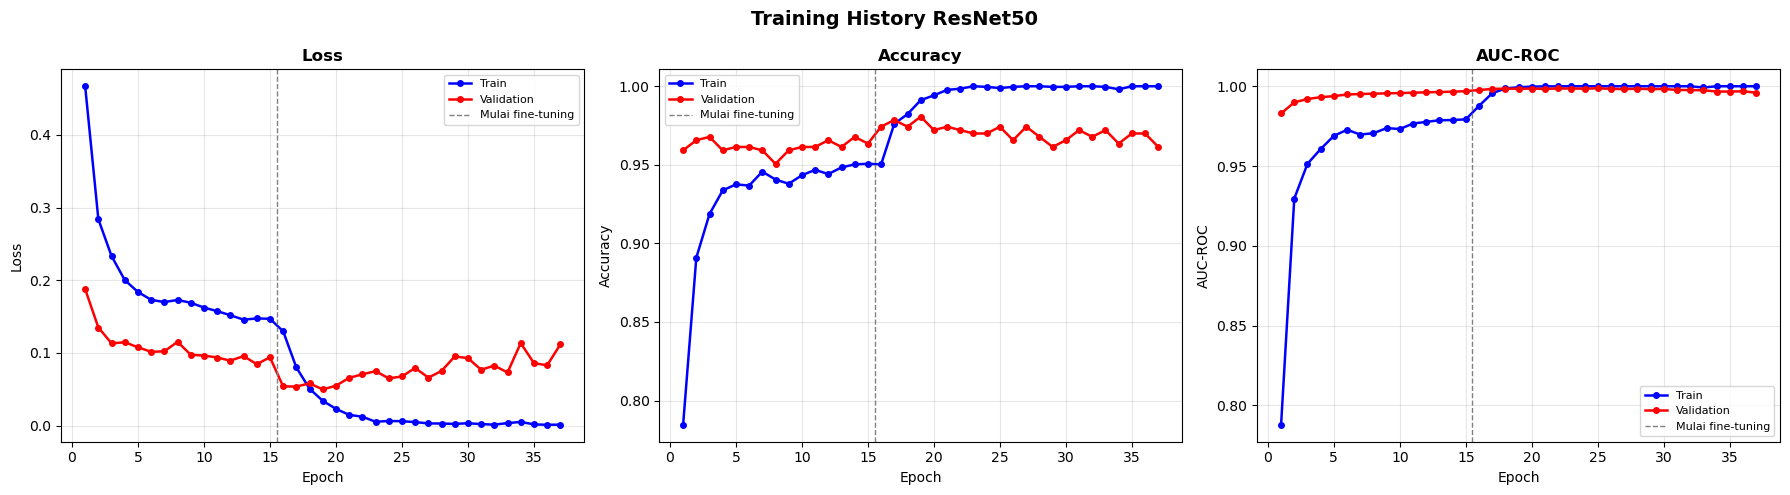

In [5]:
visualization.plot_history(hist_resnet, "ResNet50",
                           save_path=config.IMAGES_DIR / "ResNet50_training_history.png")
del model
training.free_memory()

## 4. EfficientNet-B0

In [6]:
model, hist_effnet = training.run_training("EfficientNetB0", X_train, y_train, X_val, y_val, verbose=2)
hist_effnet.to_csv(config.RESULTS_DIR / "history_EfficientNetB0.csv", index=False)

[EfficientNetB0] Train setelah oversampling: 2595 (katarak 663, normal 1932, rasio 1:2.91)
[EfficientNetB0] Parameter total: 4,050,852 | dilatih (head): 1,281
[EfficientNetB0] Fase 1: backbone beku, LR=0.0001, maks 15 epoch
Epoch 1/15

Epoch 1: val_auc improved from None to 0.69380, saving model to <ROOT>\models\EfficientNetB0_best.keras

Epoch 1: finished saving model to <ROOT>\models\EfficientNetB0_best.keras
82/82 - 46s - 564ms/step - accuracy: 0.4459 - auc: 0.4403 - loss: 0.8095 - precision: 0.2300 - recall: 0.4977 - val_accuracy: 0.8927 - val_auc: 0.6938 - val_loss: 0.4985 - val_precision: 0.3846 - val_recall: 0.1064
Epoch 2/15

Epoch 2: val_auc improved from 0.69380 to 0.96004, saving model to <ROOT>\models\EfficientNetB0_best.keras

Epoch 2: finished saving model to <ROOT>\models\EfficientNetB0_best.keras
82/82 - 34s - 412ms/step - accuracy: 0.7738 - auc: 0.7659 - loss: 0.5026 - precision: 0.6439 - recall: 0.2564 - val_accuracy: 0.9142 - val_auc: 0.9600 - val_loss: 0.3203 - val_

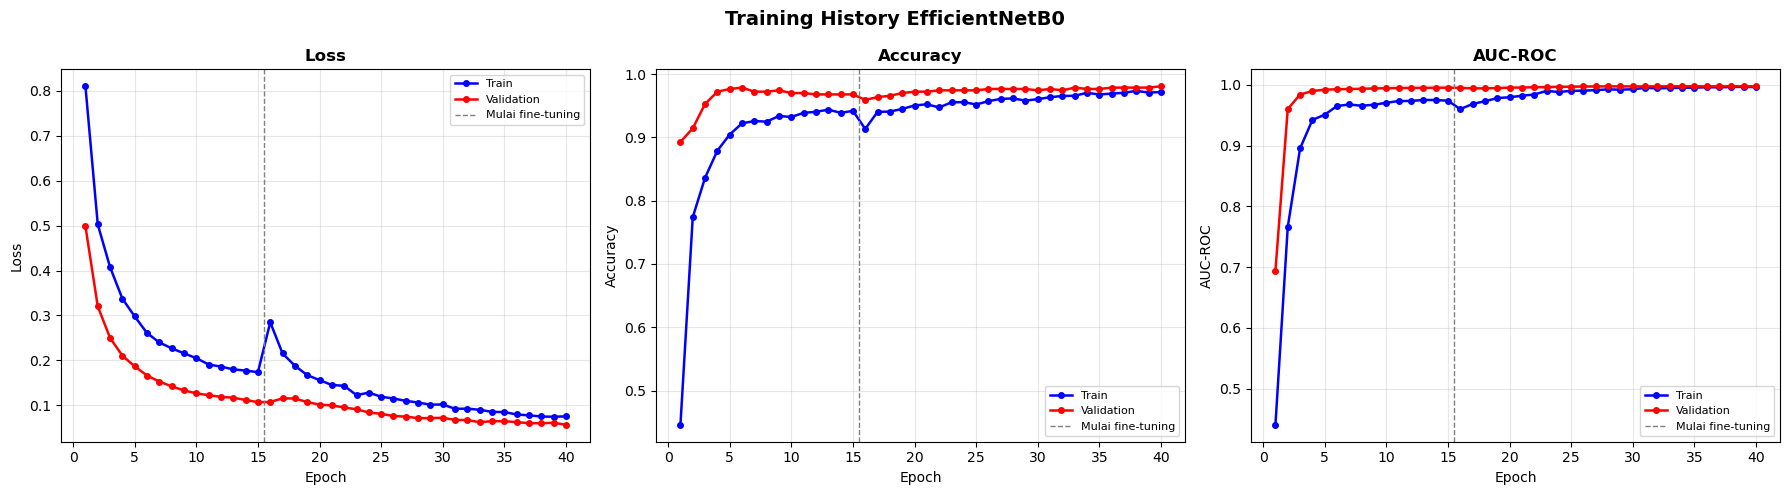

In [7]:
visualization.plot_history(hist_effnet, "EfficientNetB0",
                           save_path=config.IMAGES_DIR / "EfficientNetB0_training_history.png")
del model
training.free_memory()

## 5. Pemeriksaan overfitting

Tabel berikut membandingkan train dan validasi pada **epoch terakhir fase 2**. Epoch terakhir belum tentu epoch terbaik, karena early stopping mengembalikan bobot terbaik. Selisih positif berarti train lebih tinggi dari validasi. Untuk loss, selisih positif berarti loss train lebih tinggi.

In [8]:
rows = []
for name, hist in [("ResNet50", hist_resnet), ("EfficientNetB0", hist_effnet)]:
    last = hist[hist["phase"] == "fine_tune"].iloc[-1]
    rows.append({
        "model": name,
        "epoch_fase2": int(last["epoch"]),
        "acc_train": last["accuracy"], "acc_val": last["val_accuracy"],
        "selisih_acc": last["accuracy"] - last["val_accuracy"],
        "loss_train": last["loss"], "loss_val": last["val_loss"],
        "auc_train": last["auc"], "auc_val": last["val_auc"],
        "selisih_auc": last["auc"] - last["val_auc"],
    })
pd.DataFrame(rows).round(4)

,model,epoch_fase2,acc_train,acc_val,selisih_acc,loss_train,loss_val,auc_train,auc_val,selisih_auc
0,ResNet50,22,1.0000,0.9614,0.0386,0.0015,0.1118,1.0000,0.9960,0.0040
1,EfficientNetB0,25,0.9715,0.9807,-0.0092,0.0759,0.0570,0.9962,0.9975,-0.0013
